In [44]:
import pandas as pd
from sklearn.decomposition import PCA
import numpy as np

# Contexto

Se desea estudiar a un conjunto de clientes de una tienda retail con el objetivo de segmentarlos y ofrecerles productos dirigidos a cada segmento.

# Prepocesamiento de datos

El dataset ya viene limpio y escalado, por ende no es necesario hacerle limpieza

# Analisis exploratorio

Procedemos a revisar los tipos de datos

In [45]:
df = pd.read_csv("../utils/campana_marketing.csv")

df.head()

,Educacion,Ingresos_Anuales,CantNinnos,CantAdolescentes,DiasUltCompra,MontoVinos,MontoFrutas,MontoProductosCarneos,MontoProductosPescados,MontoProductosDulces,...,NroQuejas,Respuesta,Edad,Antiguedad,Tamano_Familia,Solo,ConPareja,Suma_Montos_Compras,Nro_Campanas_Aceptadas,Nro_Total_Compras
0,0.333333,0.503625,0.0,0.0,0.585859,0.425318,0.442211,0.316522,0.664093,0.335878,...,0.0,1.0,0.696429,1.0,0.00,1.0,0.0,0.639683,0.2,0.6875
1,0.333333,0.398325,0.5,0.5,0.383838,0.007368,0.005025,0.003478,0.007722,0.003817,...,0.0,0.0,0.750000,0.0,0.50,1.0,0.0,0.008730,0.0,0.1250
2,0.333333,0.623933,0.0,0.0,0.262626,0.285332,0.246231,0.073623,0.428571,0.080153,...,0.0,0.0,0.553571,0.5,0.25,0.0,1.0,0.305952,0.0,0.6250
3,0.333333,0.222456,0.5,0.0,0.262626,0.007368,0.020101,0.011594,0.038610,0.011450,...,0.0,0.0,0.214286,0.0,0.50,0.0,1.0,0.019048,0.0,0.1875
4,1.000000,0.505009,0.5,0.0,0.949495,0.115874,0.216080,0.068406,0.177606,0.103053,...,0.0,0.0,0.267857,0.0,0.50,0.0,1.0,0.165476,0.0,0.4375


Revisamos los tipos de datos

In [46]:
df.dtypes

Educacion                 float64
Ingresos_Anuales          float64
CantNinnos                float64
CantAdolescentes          float64
DiasUltCompra             float64
MontoVinos                float64
MontoFrutas               float64
MontoProductosCarneos     float64
MontoProductosPescados    float64
MontoProductosDulces      float64
MontoProductosSelectos    float64
NroComprasDesc            float64
NroTransacComprasWeb      float64
NroComprasCatalogo        float64
CantComprasEnTienda       float64
NroVisitasWebMensuales    float64
AceptacionCampana3        float64
AceptacionCampana4        float64
AceptacionCampana5        float64
AceptacionCampana1        float64
AceptacionCampana2        float64
NroQuejas                 float64
Respuesta                 float64
Edad                      float64
Antiguedad                float64
Tamano_Familia            float64
Solo                      float64
ConPareja                 float64
Suma_Montos_Compras       float64
Nro_Campanas_A

Todos las columans guardan tipos de datos tipo float, el cual es coherente con el hecho de que el conjunto de datos ya venia escalado.

# Reduccion de dimensionalidad

A continuacion se empieza reducir la cantidad de columnsa para que el modelo no genere sesgos o problemas relacianados con la coeficiente de variacion

## PSA

El PSA es un método lineal que preserva la variabilidad total de la información esencial.

In [47]:
# Guardamos el metodo dentro una variable, pidiendo 8 componentes
pca = PCA(n_components=8)

# metemos dentro del pca el conjunto de datos
pca.fit(df)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",8
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

Se visualiza que PCA ha registrado 31 variables originales y se retienen 8 componentes principales.

## Analisis de los 8 componentes principales

A continuacion se revisa cuanta varianza explica cada componente, la matriz de cargas (loadings) y las variables con mayor peso en cada componente.

In [48]:
# Varianza explicada individual y acumulada por cada componente
varianza = pd.DataFrame({
    "varianza_explicada": pca.explained_variance_,
    "proporcion": pca.explained_variance_ratio_,
    "proporcion_acumulada": pca.explained_variance_ratio_.cumsum(),
}, index=[f"PC{i + 1}" for i in range(pca.n_components_)])
varianza

,varianza_explicada,proporcion,proporcion_acumulada
PC1,0.487461,0.258508,0.258508
PC2,0.372442,0.197512,0.456020
PC3,0.167626,0.088895,0.544914
PC4,0.126989,0.067344,0.612259
PC5,0.115533,0.061269,0.673527
PC6,0.090081,0.047771,0.721299
PC7,0.075043,0.039797,0.761095
PC8,0.073362,0.038905,0.800000


Al analizar la salida de los primeros 8 componentes principales, observamos cómo el algoritmo comprime la dimensionalidad del dataset original preservando su estructura matemática. La columna varianza_explicada (los autovalores resultantes de la matriz de covarianza) indica la cantidad absoluta de dispersión de los datos que cada nuevo eje logra capturar, evidenciando que el PC1 retiene la mayor magnitud (0.487) y los ejes subsiguientes extraen cada vez menos. La proporcion traduce este valor a un porcentaje, revelando que el primer componente por sí solo condensa el 25.8% de toda la variabilidad de los datos, seguido por un 19.7% en el PC2. Finalmente, la proporcion_acumulada entrega el dato más crítico para la toma de decisiones: al sumar el aporte individual de estos 8 primeros componentes, se alcanza exactamente el 80.0% de la información total. Esto demuestra que es posible reemplazar la totalidad de las variables originales por estas 8 nuevas coordenadas espaciales, reteniendo la inmensa mayoría de los patrones subyacentes del modelo y filtrando el 20% restante, el cual estadísticamente suele corresponder a redundancias o ruido.

In [50]:
# Matriz de cargas (loadings): variables originales x componentes
loadings = pd.DataFrame(
    pca.components_.T,
    index=df.columns,
    columns=[f"PC{i + 1}" for i in range(pca.n_components_)],
)
loadings

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
Educacion,-0.004476,0.032645,0.027463,0.044648,0.428977,-0.109640,0.389687,0.742940
Ingresos_Anuales,-0.054389,0.243451,-0.111751,-0.040482,0.091832,-0.025079,0.020397,-0.025562
CantNinnos,0.076423,-0.273658,0.208460,0.007955,-0.018122,0.121424,0.027232,-0.053818
CantAdolescentes,0.047954,-0.061458,-0.167868,0.289041,0.571642,-0.043157,-0.008163,-0.395949
DiasUltCompra,0.008585,-0.013403,-0.202244,0.029568,-0.072984,0.778961,0.479115,-0.018134
MontoVinos,-0.067383,0.302167,-0.047830,0.061971,0.133532,0.075736,-0.009886,0.040827
MontoFrutas,-0.051467,0.190222,-0.106357,-0.038505,-0.158090,-0.101597,0.056758,-0.075150
MontoProductosCarneos,-0.041722,0.152522,-0.033941,-0.031457,-0.071632,-0.015381,0.035937,0.015146
MontoProductosPescados,-0.053833,0.210711,-0.119536,-0.045194,-0.183978,-0.095911,0.048809,-0.070904
MontoProductosDulces,-0.037814,0.150757,-0.076711,-0.025137,-0.108500,-0.040172,0.030752,-0.050650


Si revisamos PC 1 se logra ver que variables como tamaño de familia,cantidad de niños y con pareja son las que tienen mayor valor, por ende se concluye que el PC1 se fija en los estado civil. Luego PC 2 l PC2 es un eje de volumen de consumo y gasto , El PC4 es un eje de fidelidad temporal. Mide cuánto tiempo lleva el cliente con la empresa y asi sucesivamente, por ultimo en cuanta el eduacion

In [51]:
# Tres variables originales con mayor peso absoluto en cada componente
filas = []
for pc in loadings.columns:
    top = loadings[pc].abs().sort_values(ascending=False).head(3)
    for ranking, variable in enumerate(top.index, start=1):
        filas.append({
            "Componente": pc,
            "Ranking": ranking,
            "Variable": variable,
            "Carga": loadings.loc[variable, pc],
            "Peso_absoluto": abs(loadings.loc[variable, pc]),
        })

top3 = pd.DataFrame(filas)
top3

,Componente,Ranking,Variable,Carga,Peso_absoluto
0,PC1,1,ConPareja,0.660594,0.660594
1,PC1,2,Solo,-0.660594,0.660594
2,PC1,3,Tamano_Familia,0.227337,0.227337
3,PC2,1,Suma_Montos_Compras,0.352622,0.352622
4,PC2,2,Nro_Total_Compras,0.303637,0.303637
5,PC2,3,MontoVinos,0.302167,0.302167
6,PC3,1,Respuesta,0.674643,0.674643
7,PC3,2,Nro_Campanas_Aceptadas,0.297195,0.297195
8,PC3,3,AceptacionCampana3,0.251900,0.251900
9,PC4,1,Antiguedad,0.860922,0.860922


Se podria borrar cualquiera que tenga una carga negativa

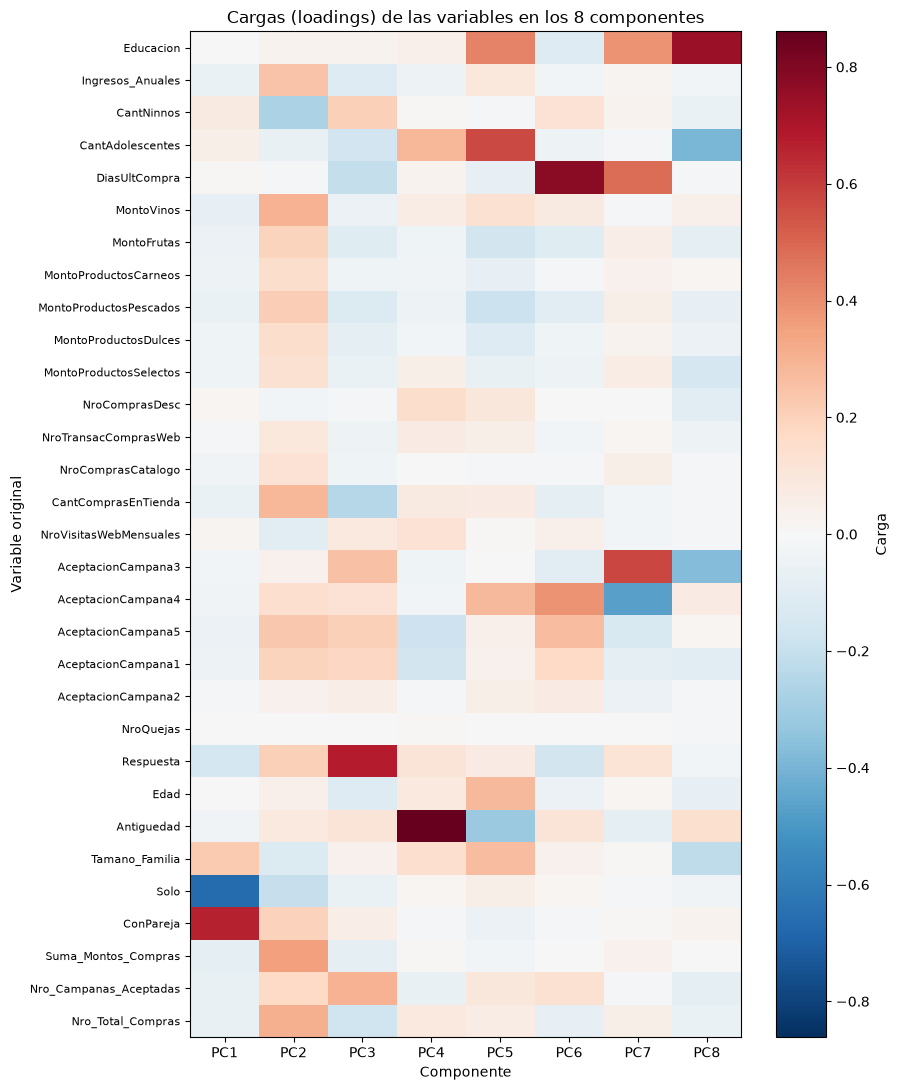

In [52]:
# Heatmap de las cargas de las variables en los 8 componentes
import matplotlib.pyplot as plt

limite = loadings.abs().max().max()

fig, ax = plt.subplots(figsize=(9, 11))
im = ax.imshow(loadings, cmap="RdBu_r", vmin=-limite, vmax=limite, aspect="auto")

ax.set_xticks(range(loadings.shape[1]))
ax.set_xticklabels(loadings.columns)
ax.set_yticks(range(loadings.shape[0]))
ax.set_yticklabels(loadings.index, fontsize=8)
ax.set_xlabel("Componente")
ax.set_ylabel("Variable original")
ax.set_title("Cargas (loadings) de las variables en los 8 componentes")

fig.colorbar(im, ax=ax, label="Carga")
plt.tight_layout()
plt.show()

## Visualizacion bidimensional con t-SNE

t-SNE es una tecnica no lineal que proyecta los datos a un espacio de menor dimension conservando las relaciones de vecindad. Se fijan 2 componentes para poder representar cada cliente en un plano.

In [53]:
from sklearn.manifold import TSNE

# Proyectamos los datos originales a 2 dimensiones
tsne = TSNE(n_components=2, random_state=42)
tsne_2d = tsne.fit_transform(df)

tsne_2d.shape

(2205, 2)

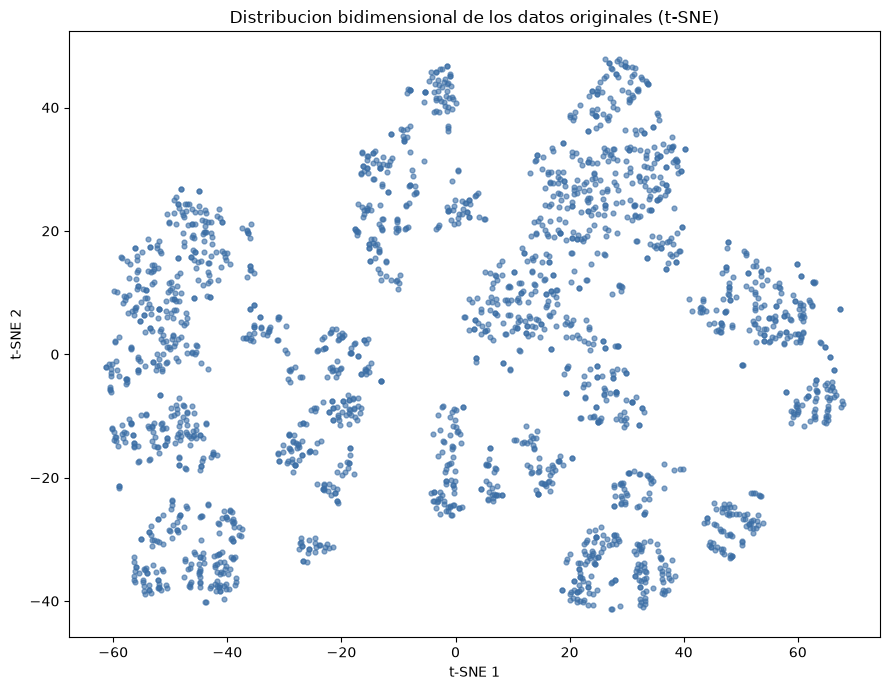

In [54]:
# Visualizacion de la distribucion bidimensional
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(tsne_2d[:, 0], tsne_2d[:, 1], s=12, alpha=0.6, c="#3b6ea5")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.set_title("Distribucion bidimensional de los datos originales (t-SNE)")
plt.tight_layout()
plt.show()